# Bilevel poisoning of SVMs in secml-torch

Port of `secml`'s `CAttackPoisoningSVM` (Biggio, Nelson, Laskov, *Poisoning attacks against SVMs*, ICML 2012).

**Contents**
1. Why the hinge loss is not a problem: implicit differentiation of the KKT conditions
2. Checks: torch SVM solver vs. libsvm, hypergradient vs. finite differences
3. 2D examples (RBF kernel), plus the special behavior of the linear kernel in low dimension
4. MNIST digits (4 vs 0), linear SVM

## 1. Hypergradient of the SVM without second derivatives of the hinge

For logistic regression we differentiated the stationarity condition $\nabla_{\boldsymbol\theta}\mathcal L=\mathbf 0$, which
needs $\nabla^2\mathcal L$. The hinge loss has no second derivative at the kink, so we change point of view and work
with the **dual**:

$$
\min_{\boldsymbol\alpha}\ \tfrac12\boldsymbol\alpha^\top\mathbf Q\boldsymbol\alpha-\mathbf 1^\top\boldsymbol\alpha
\quad\text{s.t.}\quad 0\le\alpha_i\le C,\ \ \mathbf y^\top\boldsymbol\alpha=0,
\qquad Q_{ij}=y_iy_jK(\mathbf x_i,\mathbf x_j),\qquad
f(\mathbf x)=\sum_j\alpha_jy_jK(\mathbf x,\mathbf x_j)+b .
$$

At the optimum every training point is in one of three groups (KKT conditions), with $g_i=y_if(\mathbf x_i)-1$:

| group | $\alpha_i$ | condition |
|---|---|---|
| margin SVs $\mathcal S$ | $0<\alpha_i<C$ | $g_i=0$ |
| error vectors $\mathcal E$ | $\alpha_i=C$ | $g_i\le0$ |
| reserve points $\mathcal R$ | $\alpha_i=0$ | $g_i\ge0$ |

**Key observation** (Cauwenberghs & Poggio's adiabatic update): if a poisoning point $\mathbf x_c$ moves by an infinitesimal
amount, no point changes group. Then $\alpha_{\mathcal E}=C$ and $\alpha_{\mathcal R}=0$ stay constant, and the unknowns
$\mathbf u=(\boldsymbol\alpha_{\mathcal S},b)$ are defined by **smooth equations**:

$$
F_i(\mathbf u,\mathbf x_c)=\sum_j Q_{ij}\alpha_j+y_ib-1=0\quad(i\in\mathcal S),\qquad F_0(\mathbf u)=\mathbf y^\top\boldsymbol\alpha=0 .
$$

These are linear in $\mathbf u$ and as smooth in $\mathbf x_c$ as the kernel. The implicit function theorem applies
**to these equations**, not to the training loss:

$$
\frac{d\mathbf u}{d\mathbf x_c}=-\mathbf J^{-1}\frac{\partial\mathbf F}{\partial\mathbf x_c},\qquad
\mathbf J=\begin{bmatrix}\mathbf Q_{\mathcal{SS}}&\mathbf y_{\mathcal S}\\\mathbf y_{\mathcal S}^\top&0\end{bmatrix},
\qquad
\frac{d\mathcal A}{d\mathbf x_c}=\frac{\partial\mathcal A}{\partial\mathbf x_c}-\boldsymbol\lambda^\top\frac{\partial\mathbf F}{\partial\mathbf x_c},
\quad \boldsymbol\lambda=\mathbf J^{-\top}\frac{\partial\mathcal A}{\partial\mathbf u}.
$$

$\mathbf J$ (the bordered kernel matrix of the margin SVs) plays the role of the Hessian. For a poisoning point that is not
a margin SV (the usual case, $\alpha_c=C$), this is the ICML'12 formula:

$$
\nabla_{\mathbf x_c}\mathcal A=\alpha_cy_c\Big[\sum_k\frac{\partial\ell_k}{\partial f_k}\nabla_{\mathbf x_c}K(\mathbf x_k,\mathbf x_c)
-\sum_{i\in\mathcal S}\lambda_i\,y_i\,\nabla_{\mathbf x_c}K(\mathbf x_i,\mathbf x_c)\Big].
$$

`svm_hypergradient` computes all partial derivatives with autograd, so it works for any differentiable kernel and also
covers $\mathbf x_c\in\mathcal S$.

**What is left of the non-smoothness.** The derivative is exact wherever the partition is locally constant. When a point
changes group the gradient jumps: the attacker objective is continuous but only *piecewise* smooth, like the hinge
itself. Also, $\nabla_{\mathbf x_c}\mathcal A=\mathbf 0$ if $\alpha_c=0$: a reserve point does not affect the SVM.

**Linear kernel in low dimension.** For points in general position, at most $d+1$ of them can lie exactly on the
margin, and when $n\gg d$ there are typically exactly $d+1$. In that case the $d+1$ equations
$y_i(\mathbf w^\top\mathbf x_i+b)=1$ **pin down** $(\mathbf w,b)$. Moving an error vector changes $\boldsymbol\alpha_{\mathcal S}$
but not the hyperplane, so the objective is locally *constant* and its gradient is exactly zero. This is a property
of the linear SVM, not a numerical issue. It does not occur when $|\mathcal S|<d+1$ (e.g. MNIST: $d=784$, about 100
training points) or with nonlinear kernels.

**Solver.** We need the exact partition, so the SVM is trained with an active-set QP method on the dual (each iteration
solves the KKT system above). The previous $\boldsymbol\alpha$ is used as a warm start, so retraining inside the attack
takes about a millisecond.

In [1]:
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

from secmlt_poisoning import (
    SVM,
    BilevelPoisoningSVM,
    LinearKernel,
    RBFKernel,
    mean_hinge_loss,
)

torch.set_default_dtype(torch.float64)
# Figure style of Biggio et al., ICML 2012 (original MATLAB code): default `jet` colormap,
# red/blue class dots, black SV circles, black boundary, dotted margins, black attack paths.
CMAP = "jet"
plt.rcParams.update({"figure.dpi": 110})


def accuracy(model, x, y):
    return (model.score(x).detach() > 0).long().eq(y).double().mean().item()

## 2. Checks

### Torch SVM solver vs. libsvm (scikit-learn)

In [2]:
X, Y = make_blobs(1300, centers=[[-1, -1], [1, 1]], cluster_std=0.9, random_state=0)
X, Y = torch.tensor(X), torch.tensor(Y)
x_tr, y_tr = X[:100], Y[:100]
x_val, y_val = X[100:300], Y[100:300]
x_ts, y_ts = X[300:], Y[300:]

print(f"{'kernel':22s} {'C':>6s} {'|S|':>4s} {'|E|':>4s} {'max|f - f_libsvm|':>18s} {'time':>8s}")
for kern, sk in [(LinearKernel(), dict(kernel="linear")), (RBFKernel(0.5), dict(kernel="rbf", gamma=0.5))]:
    for C in [0.1, 1.0, 100.0]:
        t0 = time.time()
        m = SVM(C, kern).fit(x_tr, y_tr)
        dt = time.time() - t0
        s = SVC(C=C, tol=1e-10, **sk).fit(x_tr.numpy(), y_tr.numpy())
        err = np.abs(m.score(x_ts).numpy() - s.decision_function(x_ts.numpy())).max()
        print(f"{str(kern):22s} {C:6g} {int(m.solution.margin.sum()):4d} {int(m.solution.error.sum()):4d} "
              f"{err:18.1e} {dt * 1e3:6.1f}ms")

kernel                      C  |S|  |E|  max|f - f_libsvm|     time
LinearKernel()            0.1    3   28            3.1e-08  101.9ms
LinearKernel()              1    3   15            5.3e-08   95.7ms
LinearKernel()            100    3    9            8.6e-06  101.0ms
RBFKernel(gamma=0.5)      0.1    7   66            4.2e-08   93.1ms
RBFKernel(gamma=0.5)        1   14   16            1.5e-07   94.2ms
RBFKernel(gamma=0.5)      100   14    7            2.1e-05   99.5ms


### Hypergradient vs. finite differences

Finite differences retrain the SVM from scratch at $\mathbf x_c\pm\epsilon\mathbf e_j$. For the linear kernel we use
$d=50$, so that $|\mathcal S|<d+1$ and the hyperplane is not pinned by the margin SVs. The last line shows the 2D case
with $|\mathcal S|=d+1=3$: the hypergradient is (correctly) zero.

In [3]:
def fd_check(kernel, x_tr, y_tr, x_val, y_val, C=1.0, eps=1e-6):
    x_p, y_p = x_tr[:3] + 0.05, 1 - y_tr[:3]
    attack = BilevelPoisoningSVM(C=C, kernel=kernel)
    g, _ = attack.gradient(x_tr, y_tr, x_p, y_p, x_val, y_val)

    def obj(z):
        attack._warm = None  # cold start: independent retraining
        return attack.objective(x_tr, y_tr, z, y_p, x_val, y_val)

    fd = torch.zeros_like(x_p)
    for i in range(x_p.shape[0]):
        for j in range(x_p.shape[1]):
            e = torch.zeros_like(x_p); e[i, j] = eps
            fd[i, j] = (obj(x_p + e) - obj(x_p - e)) / (2 * eps)
    sol = attack.train(x_tr, y_tr, x_p, y_p, warm_start=False).solution
    print(f"{str(kernel):22s} |S|={int(sol.margin.sum()):3d}  alpha_p={sol.alpha[-3:].numpy().round(3)}  "
          f"max|grad|={g.abs().max():.2e}  max|grad - fd|={(g - fd).abs().max():.2e}")


fd_check(RBFKernel(0.5), x_tr[:60], y_tr[:60], x_val, y_val)
g = torch.Generator().manual_seed(0)
y50 = torch.randint(0, 2, (140,), generator=g)
x50 = torch.randn(140, 50, generator=g) + 0.3 * (2.0 * y50[:, None] - 1)
fd_check(LinearKernel(), x50[:40], y50[:40], x50[40:], y50[40:])
print("\nlinear kernel in 2D, 100 training points (|S| = d + 1 = 3 pins the hyperplane):")
fd_check(LinearKernel(), x_tr, y_tr, x_val, y_val)

RBFKernel(gamma=0.5)   |S|= 11  alpha_p=[1. 1. 1.]  max|grad|=1.07e-02  max|grad - fd|=3.28e-11
LinearKernel()         |S|= 23  alpha_p=[1. 1. 1.]  max|grad|=2.85e-01  max|grad - fd|=1.10e-09

linear kernel in 2D, 100 training points (|S| = d + 1 = 3 pins the hyperplane):
LinearKernel()         |S|=  3  alpha_p=[1. 1. 1.]  max|grad|=3.88e-11  max|grad - fd|=1.82e-11


## 3. 2D examples

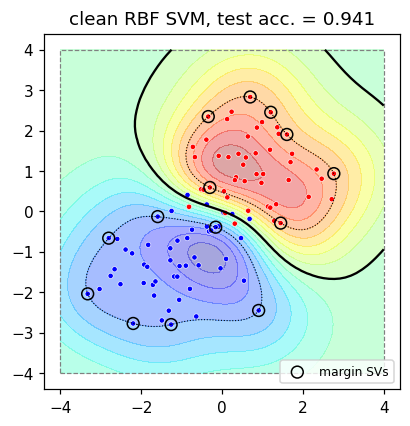

In [4]:
lb, ub = -4.0, 4.0
grid_n = 60
gx, gy = np.meshgrid(np.linspace(lb, ub, grid_n), np.linspace(lb, ub, grid_n))
grid = torch.tensor(np.c_[gx.ravel(), gy.ravel()])
COL = np.array(["b", "r"])
C, kernel = 1.0, RBFKernel(0.5)


def plot_svm(ax, model, title=None, show_sv=True):
    f = model.score(grid).detach().numpy().reshape(gx.shape)
    ax.contourf(gx, gy, f, levels=20, cmap=CMAP, alpha=0.35)
    ax.contour(gx, gy, f, levels=[-1, 0, 1], colors="k", linewidths=[0.7, 1.5, 0.7], linestyles=[":", "-", ":"])
    n_tr = len(x_tr)
    ax.scatter(*x_tr.T, c=COL[y_tr], s=12, edgecolors="w", linewidths=0.4)
    if show_sv:
        S = model.solution.margin[:n_tr].numpy()
        ax.scatter(*x_tr[S].T, s=60, facecolors="none", edgecolors="k", linewidths=1, label="margin SVs")
    ax.add_patch(plt.Rectangle((lb, lb), ub - lb, ub - lb, fill=False, ls="--", lw=0.8, ec="gray"))
    ax.set_xlim(lb - 0.4, ub + 0.4); ax.set_ylim(lb - 0.4, ub + 0.4); ax.set_aspect("equal")
    if title: ax.set_title(title)


clean = SVM(C, kernel).fit(x_tr, y_tr)
fig, ax = plt.subplots(figsize=(4.2, 4.2))
plot_svm(ax, clean, f"clean RBF SVM, test acc. = {accuracy(clean, x_ts, y_ts):.3f}")
ax.legend(loc="lower right", fontsize=8)

### Attacker-loss landscape for a single poisoning point (RBF kernel)

For every location of the poisoning point we retrain the SVM and compute the average hinge loss on the validation set.
The arrows are the normalized hypergradients. Where they vanish, the poisoning point has $\alpha_c=0$ (it lies on
the correct side of the margin for its label), so it has no influence on the SVM.

7200 retrainings + 392 hypergradients in 11.0s


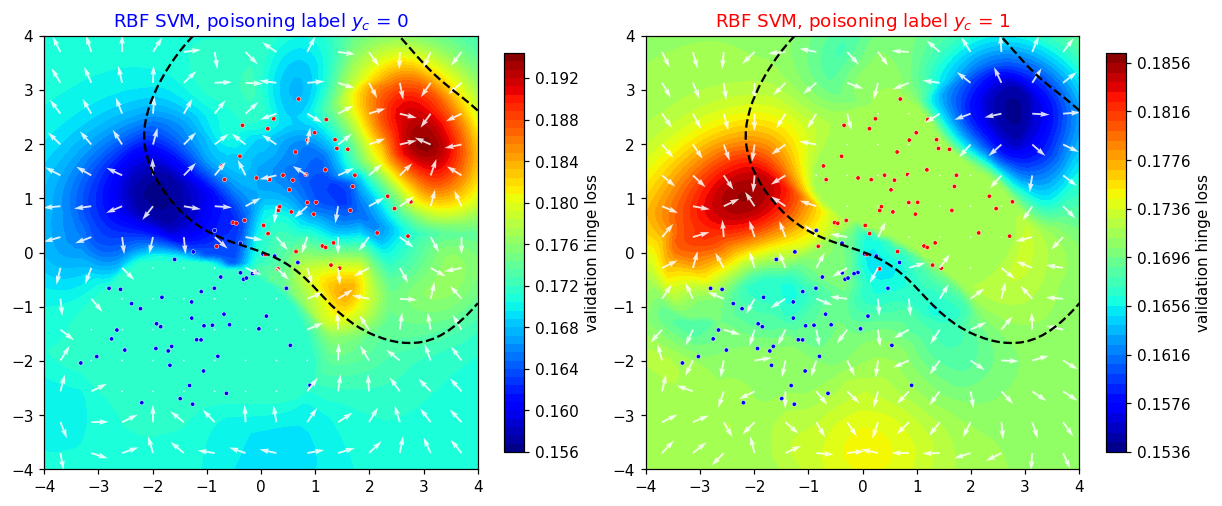

In [5]:
def landscape(attack, yc, pts):
    ycs = torch.tensor([yc])
    return np.array([attack.objective(x_tr, y_tr, xc[None], ycs, x_val, y_val).item() for xc in pts])


def grad_field(attack, yc, pts):
    ycs = torch.tensor([yc])
    G = np.stack([attack.gradient(x_tr, y_tr, xc[None], ycs, x_val, y_val)[0][0].numpy() for xc in pts])
    nrm = np.linalg.norm(G, axis=1, keepdims=True)
    return np.where(nrm > 1e-8, G / np.maximum(nrm, 1e-300), 0.0)


q = np.linspace(lb + 0.3, ub - 0.3, 14)
qx, qy = np.meshgrid(q, q)
qgrid = torch.tensor(np.c_[qx.ravel(), qy.ravel()])

attack = BilevelPoisoningSVM(C=C, kernel=kernel, lb=lb, ub=ub)
land = {}
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
t0 = time.time()
for ax, yc in zip(axs, [0, 1]):
    land[yc] = landscape(attack, yc, grid).reshape(gx.shape)
    G = grad_field(attack, yc, qgrid)
    cs = ax.contourf(gx, gy, land[yc], levels=50, cmap=CMAP)
    plt.colorbar(cs, ax=ax, fraction=0.046, label="validation hinge loss")
    ax.contour(gx, gy, clean.score(grid).numpy().reshape(gx.shape), levels=[0], colors="k", linestyles="--")
    ax.scatter(*x_tr.T, c=COL[y_tr], s=8, edgecolors="w", linewidths=0.3)
    ax.quiver(qx, qy, G[:, 0].reshape(qx.shape), G[:, 1].reshape(qx.shape), color="w", alpha=0.85, scale=25)
    ax.set_title(f"RBF SVM, poisoning label $y_c$ = {yc}", color=COL[yc]); ax.set_aspect("equal")
print(f"{2 * len(grid)} retrainings + {2 * len(qgrid)} hypergradients in {time.time() - t0:.1f}s")

### The linear kernel in 2D: a piecewise-constant landscape

Same plot for a linear SVM. The landscape is mostly made of flat regions. Wherever three points lie on the margin,
they fix the hyperplane, so moving the poisoning point has no effect and the hypergradient is exactly zero (no arrows).
Arrows only appear where the current partition has fewer than $d+1=3$ margin SVs. The attacker loss only changes when the poisoning point (or its effect on $\boldsymbol\alpha$) changes the
partition. This is the "second-derivative problem" in another form: a gradient-based attack has no local signal here.
In high dimension (MNIST below) $|\mathcal S| \ll d+1$ and this does not happen.

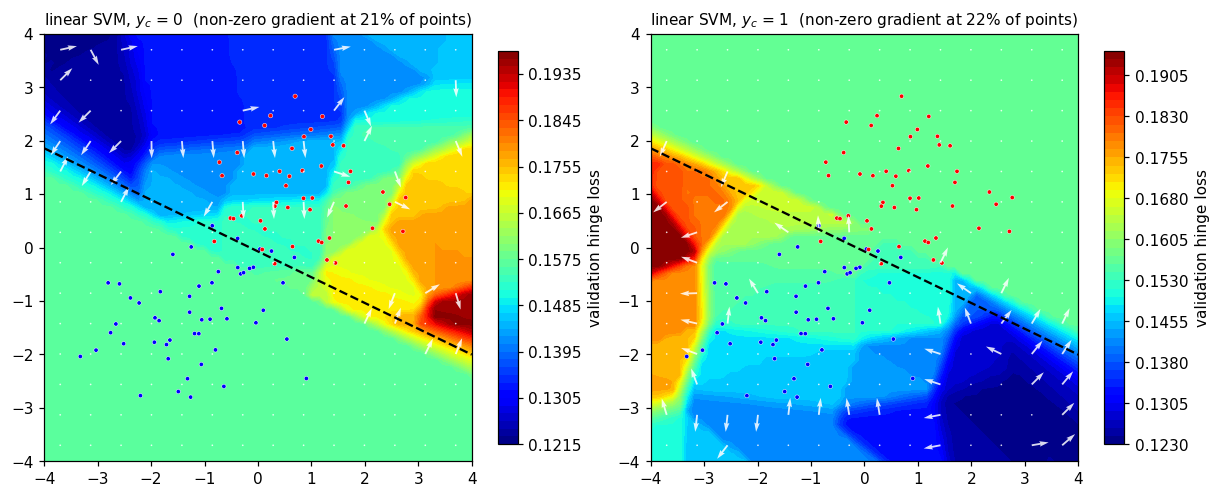

In [6]:
attack_lin = BilevelPoisoningSVM(C=C, kernel=LinearKernel(), lb=lb, ub=ub)
clean_lin = SVM(C, LinearKernel()).fit(x_tr, y_tr)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
for ax, yc in zip(axs, [0, 1]):
    L = landscape(attack_lin, yc, grid).reshape(gx.shape)
    G = grad_field(attack_lin, yc, qgrid)
    cs = ax.contourf(gx, gy, L, levels=50, cmap=CMAP)
    plt.colorbar(cs, ax=ax, fraction=0.046, label="validation hinge loss")
    ax.contour(gx, gy, clean_lin.score(grid).numpy().reshape(gx.shape), levels=[0], colors="k", linestyles="--")
    ax.scatter(*x_tr.T, c=COL[y_tr], s=8, edgecolors="w", linewidths=0.3)
    ax.quiver(qx, qy, G[:, 0].reshape(qx.shape), G[:, 1].reshape(qx.shape), color="w", alpha=0.85, scale=25)
    nz = (np.abs(G).sum(1) > 0).mean()
    ax.set_title(f"linear SVM, $y_c$ = {yc}  (non-zero gradient at {100 * nz:.0f}% of points)", fontsize=10)
    ax.set_aspect("equal")

### Single-point attack trajectories (RBF kernel)

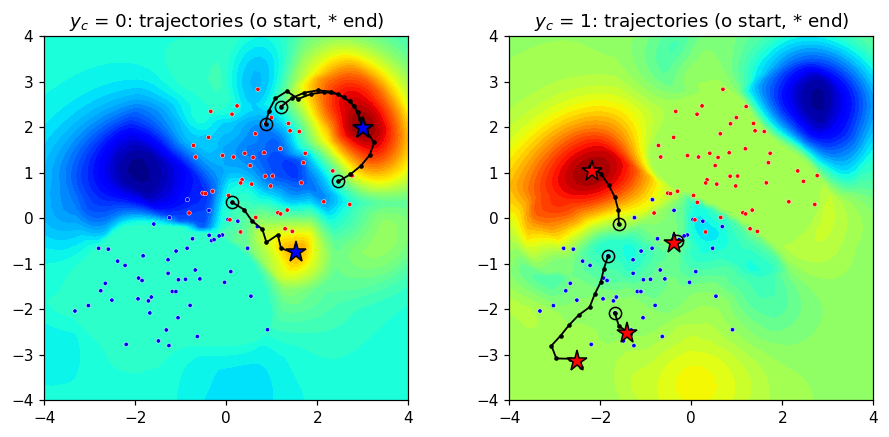

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.3))
starts = [x_tr[y_tr == 1][:4], x_tr[y_tr == 0][:4]]  # yc = 0 starts from class-1 points and vice versa
for ax, yc, x0s in zip(axs, [0, 1], starts):
    ax.contourf(gx, gy, land[yc], levels=50, cmap=CMAP)
    ax.scatter(*x_tr.T, c=COL[y_tr], s=8, edgecolors="w", linewidths=0.3)
    for x0 in x0s:
        att = BilevelPoisoningSVM(C=C, kernel=kernel, lb=lb, ub=ub, step_size=0.3, max_iter=100, store_path=True)
        res = att.run(x_tr, y_tr, x_val, y_val, x_init=x0[None], y_init=torch.tensor([yc]))
        path = torch.stack(res.history["x_poison"])[:, 0].numpy()
        ax.plot(*path.T, "k.-", lw=1.2, ms=4)
        ax.plot(*path[0], "o", mfc="none", mec="k", ms=8)
        ax.plot(*path[-1], "*", color=COL[yc], mec="k", ms=14, clip_on=False)
    ax.set_title(f"$y_c$ = {yc}: trajectories (o start, * end)"); ax.set_aspect("equal")
    ax.set_xlim(lb, ub); ax.set_ylim(lb, ub)

Unlike logistic regression, the optimal points do not go to the corners of the box. With an RBF kernel a point far
from the data has no effect on the classifier, so the best locations are near the data, on the wrong side of the
boundary. This is the behavior reported in the ICML'12 paper.

### Multiple poisoning points (RBF kernel)

attack time 0.42s, 35 iterations
alpha of the poisoning points: [1.    0.    1.    0.684 1.    1.    1.    1.    0.    1.   ]


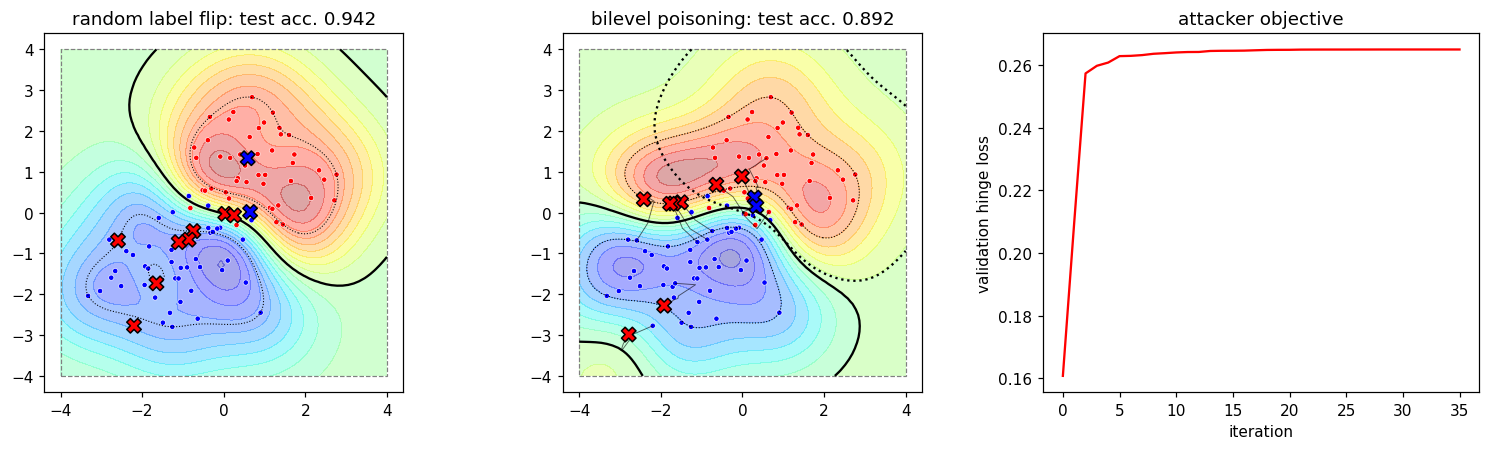

In [8]:
n_p = 10
attack = BilevelPoisoningSVM(C=C, kernel=kernel, lb=lb, ub=ub, step_size=0.5, max_iter=200, tol=1e-8,
                             random_seed=0, store_path=True)
t0 = time.time()
res = attack.run(x_tr, y_tr, x_val, y_val, n_points=n_p)
print(f"attack time {time.time() - t0:.2f}s, {len(res.history['objective']) - 1} iterations")
x0 = res.history["x_poison"][0]
flip = SVM(C, kernel).fit(torch.cat([x_tr, x0]), torch.cat([y_tr, res.y_poison]))

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
plot_svm(axs[0], flip, f"random label flip: test acc. {accuracy(flip, x_ts, y_ts):.3f}", show_sv=False)
axs[0].scatter(*x0.T, c=COL[res.y_poison], marker="X", s=90, edgecolors="k", zorder=5)
plot_svm(axs[1], res.model, f"bilevel poisoning: test acc. {accuracy(res.model, x_ts, y_ts):.3f}", show_sv=False)
paths = torch.stack(res.history["x_poison"]).numpy()
for i in range(n_p):
    axs[1].plot(*paths[:, i].T, "k-", lw=0.6, alpha=0.6)
axs[1].scatter(*res.x_poison.T, c=COL[res.y_poison], marker="X", s=90, edgecolors="k", zorder=5, clip_on=False)
axs[1].contour(gx, gy, clean.score(grid).numpy().reshape(gx.shape), levels=[0], colors="k", linestyles=":")
axs[2].plot(res.history["objective"], "r-")
axs[2].set_xlabel("iteration"); axs[2].set_ylabel("validation hinge loss"); axs[2].set_title("attacker objective")
plt.tight_layout()
print("alpha of the poisoning points:", res.model.solution.alpha[-n_p:].numpy().round(3))

### Test accuracy vs. fraction of poisoning points (2D, RBF kernel)

22.3s


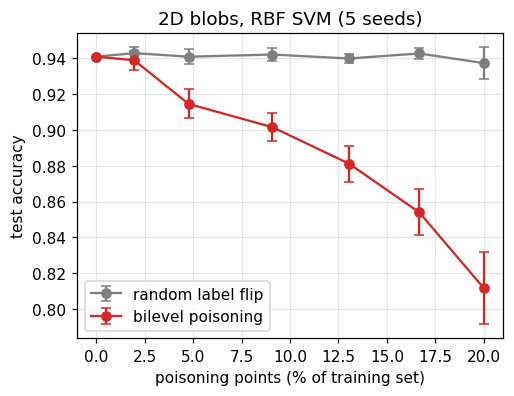

In [9]:
def curve(x_tr, y_tr, x_val, y_val, x_ts, y_ts, n_points, seeds, **attack_kw):
    acc_atk, acc_flip = np.zeros((len(seeds), len(n_points))), np.zeros((len(seeds), len(n_points)))
    for i, s in enumerate(seeds):
        for j, n in enumerate(n_points):
            if n == 0:
                m = SVM(attack_kw["C"], attack_kw.get("kernel")).fit(x_tr, y_tr)
                acc_atk[i, j] = acc_flip[i, j] = accuracy(m, x_ts, y_ts)
                continue
            # max_iter=0 -> classifier trained on the random label-flip initialization
            r0 = BilevelPoisoningSVM(**{**attack_kw, "max_iter": 0}, random_seed=s).run(
                x_tr, y_tr, x_val, y_val, n_points=n)
            r = BilevelPoisoningSVM(**attack_kw, random_seed=s).run(x_tr, y_tr, x_val, y_val, n_points=n)
            acc_flip[i, j], acc_atk[i, j] = accuracy(r0.model, x_ts, y_ts), accuracy(r.model, x_ts, y_ts)
    return acc_atk, acc_flip


def plot_curve(ax, n_points, n_tr, acc_atk, acc_flip, title):
    frac = 100 * np.array(n_points) / (n_tr + np.array(n_points))
    for a, lab, c in [(acc_flip, "random label flip", "tab:gray"), (acc_atk, "bilevel poisoning", "tab:red")]:
        ax.errorbar(frac, a.mean(0), yerr=a.std(0), marker="o", label=lab, color=c, capsize=3)
    ax.set_xlabel("poisoning points (% of training set)"); ax.set_ylabel("test accuracy")
    ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)


n_points_2d = [0, 2, 5, 10, 15, 20, 25]
t0 = time.time()
acc_atk, acc_flip = curve(x_tr, y_tr, x_val, y_val, x_ts, y_ts, n_points_2d, seeds=range(5),
                          C=C, kernel=kernel, lb=lb, ub=ub, step_size=0.5, max_iter=200, tol=1e-8)
print(f"{time.time() - t0:.1f}s")
fig, ax = plt.subplots(figsize=(5, 3.6))
plot_curve(ax, n_points_2d, len(x_tr), acc_atk, acc_flip, "2D blobs, RBF SVM (5 seeds)")

## 4. MNIST digits: 4 vs 0, linear SVM

Same setup as the logistic-regression notebook: 100 training samples, 500 validation samples for the attacker, and 2000
test samples, with box $[0,1]^{784}$. Here $d+1=785\gg|\mathcal S|$, so the hyperplane is not pinned and gradients are
informative.

In [10]:
from torchvision.datasets import MNIST

mnist = MNIST(root="~/.pytorch", train=True, download=True)
digits = (4, 0)  # class 1 = "4", class 0 = "0"
mask = (mnist.targets == digits[0]) | (mnist.targets == digits[1])
x = mnist.data[mask].reshape(-1, 784).double() / 255.0
y = (mnist.targets[mask] == digits[0]).long()
perm = torch.randperm(len(x), generator=torch.Generator().manual_seed(0))
x, y = x[perm], y[perm]
xm_tr, ym_tr = x[:100], y[:100]
xm_val, ym_val = x[100:600], y[100:600]
xm_ts, ym_ts = x[600:2600], y[600:2600]

Cm = 1.0
clean_m = SVM(Cm).fit(xm_tr, ym_tr)
s = clean_m.solution
print(f"clean test accuracy: {accuracy(clean_m, xm_ts, ym_ts):.4f}  "
      f"(|S| = {int(s.margin.sum())}, |E| = {int(s.error.sum())})")

clean test accuracy: 0.9950  (|S| = 25, |E| = 0)


attack time 0.9s, 49 iterations
test accuracy  clean: 0.9950 | label flip: 0.9915 | bilevel poisoning: 0.5190
alpha of the poisoning points: [1.    1.    1.    1.    0.962 1.    1.    1.    0.574 1.   ]


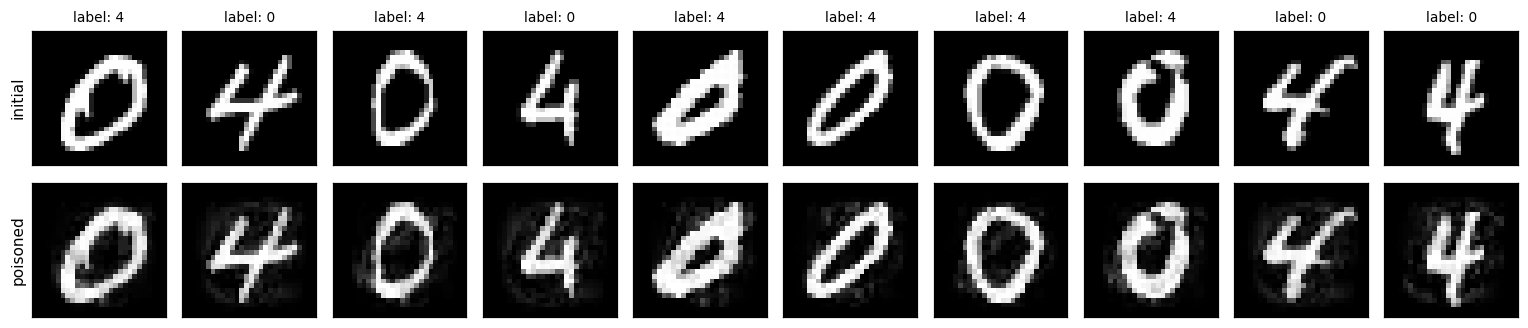

In [11]:
n_pm = 10
attack_m = BilevelPoisoningSVM(C=Cm, lb=0.0, ub=1.0, step_size=2.0, max_iter=200, tol=1e-8,
                               random_seed=0, store_path=True)
t0 = time.time()
res_m = attack_m.run(xm_tr, ym_tr, xm_val, ym_val, n_points=n_pm)
print(f"attack time {time.time() - t0:.1f}s, {len(res_m.history['objective']) - 1} iterations")

x0m = res_m.history["x_poison"][0]
flip_m = SVM(Cm).fit(torch.cat([xm_tr, x0m]), torch.cat([ym_tr, res_m.y_poison]))
print(f"test accuracy  clean: {accuracy(clean_m, xm_ts, ym_ts):.4f} | "
      f"label flip: {accuracy(flip_m, xm_ts, ym_ts):.4f} | "
      f"bilevel poisoning: {accuracy(res_m.model, xm_ts, ym_ts):.4f}")
print("alpha of the poisoning points:", res_m.model.solution.alpha[-n_pm:].numpy().round(3))

fig, axs = plt.subplots(2, n_pm, figsize=(1.4 * n_pm, 3.2))
for i in range(n_pm):
    lab = digits[0] if res_m.y_poison[i] == 1 else digits[1]
    axs[0, i].imshow(x0m[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axs[1, i].imshow(res_m.x_poison[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axs[0, i].set_title(f"label: {lab}", fontsize=9)
    for a in axs[:, i]: a.set_xticks([]); a.set_yticks([])
axs[0, 0].set_ylabel("initial"); axs[1, 0].set_ylabel("poisoned")
plt.tight_layout()

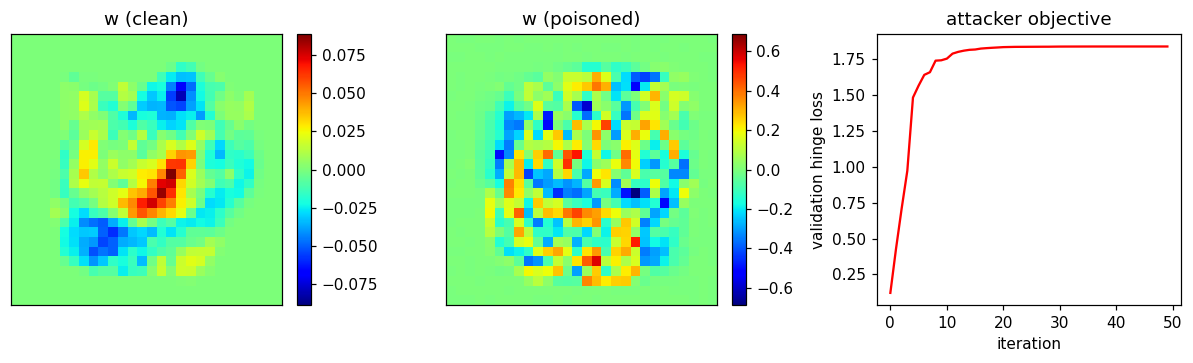

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, m, t in [(axs[0], clean_m, "w (clean)"), (axs[1], res_m.model, "w (poisoned)")]:
    w_img = m.weight.reshape(28, 28)
    v = w_img.abs().max()
    im = ax.imshow(w_img, cmap=CMAP, vmin=-v, vmax=v); ax.set_title(t)
    ax.set_xticks([]); ax.set_yticks([]); plt.colorbar(im, ax=ax, fraction=0.046)
axs[2].plot(res_m.history["objective"], "r-"); axs[2].set_xlabel("iteration")
axs[2].set_ylabel("validation hinge loss"); axs[2].set_title("attacker objective")
plt.tight_layout()

### Test accuracy vs. fraction of poisoning points (MNIST 4 vs 0, linear SVM)

16.2s


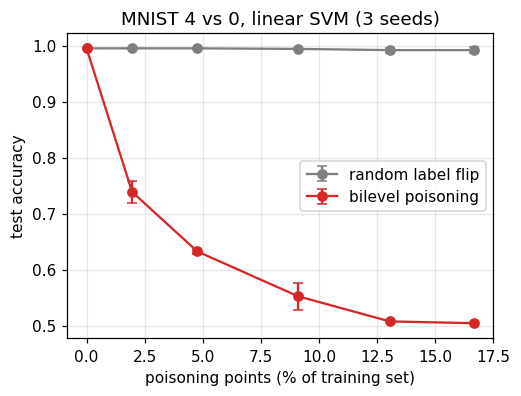

In [13]:
n_points_m = [0, 2, 5, 10, 15, 20]
t0 = time.time()
acc_atk_m, acc_flip_m = curve(xm_tr, ym_tr, xm_val, ym_val, xm_ts, ym_ts, n_points_m, seeds=range(3),
                              C=Cm, kernel=LinearKernel(), lb=0.0, ub=1.0, step_size=2.0, max_iter=100, tol=1e-8)
print(f"{time.time() - t0:.1f}s")
fig, ax = plt.subplots(figsize=(5, 3.6))
plot_curve(ax, n_points_m, len(xm_tr), acc_atk_m, acc_flip_m, "MNIST 4 vs 0, linear SVM (3 seeds)")

## Notes

* **Second derivatives.** None are needed: we differentiate the KKT equalities of the margin SVs, which are smooth for a
  fixed partition. The non-smoothness of the hinge shows up as kinks of the attacker objective (partition changes) and
  as zero gradients for points with $\alpha_c=0$.
* **Exactness.** The hypergradient matches finite differences to about 1e-10 when the partition is stable. This requires
  the exact partition, hence the active-set solver (an approximate SGD-trained SVM would not provide it).
* **Linear kernel, low dimension.** When $|\mathcal S|=d+1$ the margin SVs pin the hyperplane, and the hypergradient
  vanishes almost everywhere. Smoothed surrogates (e.g. a smoothed hinge, or the logistic regression attack used as a
  surrogate) are the usual way out.
* **Differences from secml.** All points are optimized jointly. Also, the case where a poisoning point is itself a
  margin SV is handled exactly; secml only kept the cross-kernel term.